In [1]:
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, sys, re

In [2]:
adata = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/interim/single-cell/10Xv3_subsampled.h5ad')
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/interim/spatial/Zhuang-ABCA-4_aggregated.h5ad')
st_data.var_names = st_data.var['gene_identifier']
gene_overlap = list(set(st_data.var_names).intersection(set(adata.var_names)))
st_data = st_data[:,gene_overlap]
adata = adata[:,gene_overlap]

In [3]:
st_data.shape,adata.shape

((215278, 1122), (271164, 1122))

In [4]:
st_data.obs['brain_section_label'].unique()

['Zhuang-ABCA-4.002', 'Zhuang-ABCA-4.003', 'Zhuang-ABCA-4.001']
Categories (3, object): ['Zhuang-ABCA-4.001', 'Zhuang-ABCA-4.002', 'Zhuang-ABCA-4.003']

In [5]:
sys.path.append('/home/jwinchel/Syndri/code/')
import importlib
import mapping
importlib.reload(mapping)
from mapping import integrate_single_st_file_with_harmony

slices = list(st_data.obs['brain_section_label'].unique())

st_data_list = []
for sl in slices:
    # print(sl,st_data.obs['slice'].unique(),len(st_data[st_data.obs['slice']==str(sl)]))
    adata,sl_adata, _ = integrate_single_st_file_with_harmony(st_data[st_data.obs['brain_section_label']==str(sl)], adata,tissue_filter=None,n_pcs=30,tissue_name=str(sl))
    st_data_list.append(sl_adata)



/home/jwinchel/Syndri/code/mapping.py:61: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  st_data.obs["batch"] = "st"
/home/jwinchel/Syndri/code/mapping.py:64: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = sc_data.concatenate(
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/_core/merge.py:1349: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  concat_annot = pd.concat(
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/_core/merge.py:1349: FutureWarning: Th

['cell_barcode', 'barcoded_cell_sample_label', 'library_label', 'feature_matrix_label', 'entity', 'brain_section_label', 'library_method', 'region_of_interest_acronym', 'donor_label', 'donor_genotype', 'donor_sex', 'dataset_label', 'x', 'y', 'cluster_alias', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color', 'region_of_interest_order', 'region_of_interest_color', 'batch', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer']
category
batch
sc    271164
st     66473
Name: count, dtype: int64
(337637, 30)


2026-09-10 15:55:03,490 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-09-10 15:55:37,764 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-09-10 15:55:39,688 - harmonypy - INFO - Iteration 1 of 30
2026-09-10 15:58:13,253 - harmonypy - INFO - Iteration 2 of 30
2026-09-10 16:01:01,856 - harmonypy - INFO - Iteration 3 of 30
2026-09-10 16:03:57,402 - harmonypy - INFO - Iteration 4 of 30
2026-09-10 16:06:39,709 - harmonypy - INFO - Iteration 5 of 30
2026-09-10 16:09:10,490 - harmonypy - INFO - Iteration 6 of 30
2026-09-10 16:11:33,283 - harmonypy - INFO - Iteration 7 of 30
2026-09-10 16:14:36,720 - harmonypy - INFO - Iteration 8 of 30
2026-09-10 16:16:48,810 - harmonypy - INFO - Converged after 8 iterations
/home/jwinchel/Syndri/code/mapping.py:61: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  st_data.obs["batch"] = "st"
/home/jwinchel/Syndri/code/mapping.py:64: FutureWarning: Use anndata

['cell_barcode', 'barcoded_cell_sample_label', 'library_label', 'feature_matrix_label', 'entity', 'brain_section_label', 'library_method', 'region_of_interest_acronym', 'donor_label', 'donor_genotype', 'donor_sex', 'dataset_label', 'x', 'y', 'cluster_alias', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color', 'region_of_interest_order', 'region_of_interest_color', 'batch', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer']
category
batch
sc    271164
st     95104
Name: count, dtype: int64
(366268, 30)


2026-09-10 16:18:22,666 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-09-10 16:18:24,710 - harmonypy - INFO - Iteration 1 of 30
2026-09-10 16:21:44,887 - harmonypy - INFO - Iteration 2 of 30
2026-09-10 16:25:49,664 - harmonypy - INFO - Iteration 3 of 30
2026-09-10 16:29:40,267 - harmonypy - INFO - Iteration 4 of 30
2026-09-10 16:33:06,463 - harmonypy - INFO - Iteration 5 of 30
2026-09-10 16:35:05,400 - harmonypy - INFO - Iteration 6 of 30
2026-09-10 16:36:03,884 - harmonypy - INFO - Converged after 6 iterations
/home/jwinchel/Syndri/code/mapping.py:61: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  st_data.obs["batch"] = "st"
/home/jwinchel/Syndri/code/mapping.py:64: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = sc_data.con

['cell_barcode', 'barcoded_cell_sample_label', 'library_label', 'feature_matrix_label', 'entity', 'brain_section_label', 'library_method', 'region_of_interest_acronym', 'donor_label', 'donor_genotype', 'donor_sex', 'dataset_label', 'x', 'y', 'cluster_alias', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color', 'region_of_interest_order', 'region_of_interest_color', 'batch', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer']
category
batch
sc    271164
st     53701
Name: count, dtype: int64
(324865, 30)


2026-09-10 16:37:09,035 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-09-10 16:37:10,958 - harmonypy - INFO - Iteration 1 of 30
2026-09-10 16:40:05,459 - harmonypy - INFO - Iteration 2 of 30
2026-09-10 16:42:53,330 - harmonypy - INFO - Iteration 3 of 30
2026-09-10 16:45:56,753 - harmonypy - INFO - Iteration 4 of 30
2026-09-10 16:49:10,835 - harmonypy - INFO - Iteration 5 of 30
2026-09-10 16:52:11,881 - harmonypy - INFO - Iteration 6 of 30
2026-09-10 16:55:03,859 - harmonypy - INFO - Converged after 6 iterations


In [9]:
adata.obs['cell_label']

KeyError: 'cell_label'

In [12]:
ad.settings.allow_write_nullable_strings = True
adata.write_h5ad('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/interim/single-cell/sc_integrated.h5ad')

In [16]:
st_data_list[0]

AnnData object with n_obs × n_vars = 66473 × 1122
    obs: 'brain_section_label', 'feature_matrix_label', 'donor_label', 'donor_genotype', 'donor_sex', 'cluster_alias', 'x', 'y', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color', 'batch'
    var: 'gene_symbol', 'gene_identifier', 'name', 'mapped_ncbi_identifier'
    obsm: 'X_pca_harmony_Zhuang_ABCA_4_002'

In [19]:
list(st_data_list[0].obsm.keys())

['X_pca_harmony_Zhuang_ABCA_4_002']

In [20]:
slices = list(st_data.obs['brain_section_label'].unique())
combined = np.full((st_data.n_obs,30),np.nan,dtype=adata.obsm['X_pca_harmony_Zhuang_ABCA_4_003'].dtype)

# map full adata cell IDs -> row indices
obs_to_idx = {
    obs_name: i
    for i, obs_name in enumerate(st_data.obs_names)
}

for i,subset in enumerate(st_data_list):
    idx = np.array([
        obs_to_idx[obs_name]
        for obs_name in subset.obs_names
    ])
    harmony_layer = [k for k in list(subset.obsm.keys()) if "X_pca_harmony" in k][0]
    combined[idx] = subset.obsm[harmony_layer]

st_data.obsm['X_pca_harmony'] = combined
st_data

/tmp/ipykernel_2176340/185040764.py:18: ImplicitModificationWarning: Setting element `.obsm['X_pca_harmony']` of view, initializing view as actual.
  st_data.obsm['X_pca_harmony'] = combined


AnnData object with n_obs × n_vars = 215278 × 1122
    obs: 'brain_section_label', 'feature_matrix_label', 'donor_label', 'donor_genotype', 'donor_sex', 'cluster_alias', 'x', 'y', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color'
    var: 'gene_symbol', 'gene_identifier', 'name', 'mapped_ncbi_identifier'
    obsm: 'X_pca_harmony'

In [21]:
st_data

AnnData object with n_obs × n_vars = 215278 × 1122
    obs: 'brain_section_label', 'feature_matrix_label', 'donor_label', 'donor_genotype', 'donor_sex', 'cluster_alias', 'x', 'y', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color'
    var: 'gene_symbol', 'gene_identifier', 'name', 'mapped_ncbi_identifier'
    obsm: 'X_pca_harmony'

In [22]:
slices

['Zhuang-ABCA-4.002', 'Zhuang-ABCA-4.003', 'Zhuang-ABCA-4.001']

In [23]:
for sl in slices:
    st_data[st_data.obs['brain_section_label']==sl].write_h5ad(f'/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/interim/spatial/st_integrated_slice-{sl}.h5ad')

In [28]:
del st_data_list

In [ ]:
adata.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony_0'].copy()

In [29]:
st_data[st_data.obs['brain_section_label']==slices[1]].obs#['class'].value_counts()

,brain_section_label,feature_matrix_label,donor_label,donor_genotype,donor_sex,cluster_alias,x,y,z,subclass_confidence_score,...,neurotransmitter,class,subclass,supertype,cluster,neurotransmitter_color,class_color,subclass_color,supertype_color,cluster_color
cell_label,,,,,,,,,,,,,,,,,,,,,
21206401769937221083122136296538173909,Zhuang-ABCA-4.003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
277134087951242341079965334096123239254,Zhuang-ABCA-4.003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
334310951043655619019872542017748449013,Zhuang-ABCA-4.003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
38609700653208821602379573311775724127,Zhuang-ABCA-4.003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
116059015578626061490334516044419146715,Zhuang-ABCA-4.003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313124108948606490566007331658286255326,Zhuang-ABCA-4.003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
230673448897725728984200659886375726831,Zhuang-ABCA-4.003,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,5212.0,3.128674,3.536740,2.914369,0.999963,...,NaN,31 OPC-Oligo,327 Oligo NN,1181 COP NN_1,5273 COP NN_1,#666666,#03045E,#99FFBC,#609945,#CC915C
151886877836311820424259180165663269959,Zhuang-ABCA-4.003,Zhuang-ABCA-4,Zhuang-ABCA-4,wt/wt,M,5231.0,2.959670,3.215968,2.914369,0.999974,...,NaN,31 OPC-Oligo,327 Oligo NN,1184 MOL NN_4,5285 MOL NN_4,#666666,#03045E,#99FFBC,#99CAFF,#5A662E


In [31]:
adata

AnnData object with n_obs × n_vars = 271164 × 1122
    obs: 'cell_barcode', 'barcoded_cell_sample_label', 'library_label', 'feature_matrix_label', 'entity', 'brain_section_label', 'library_method', 'region_of_interest_acronym', 'donor_label', 'donor_genotype', 'donor_sex', 'dataset_label', 'x', 'y', 'cluster_alias', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color', 'region_of_interest_order', 'region_of_interest_color', 'batch'
    var: 'gene_symbol'
    obsm: 'X_pca_harmony_Zhuang_ABCA_4_002', 'X_pca_harmony_Zhuang_ABCA_4_003', 'X_pca_harmony_Zhuang_ABCA_4_001'

In [36]:
# read in previously saved single-cell and spatial data
adata=ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/interim/single-cell/sc_integrated.h5ad')
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/interim/spatial/st_integrated_slice-Zhuang-ABCA-4.003.h5ad')
# st_data.obs[['center_x','center_y']] = st_data.obs[['center_x','center_y']].astype(float)
# st_data.obs[['min_x','min_y']] = st_data.obs[['min_x','min_y']].astype(float)
# st_data = st_data[st_data.obs['age']=='90wk']
adata.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony_Zhuang_ABCA_4_003'].copy()

In [ ]:
# # drop a few T-cells
# rng = np.random.default_rng(0)
# t_idx = np.flatnonzero(adata.obs["cell_type"].eq("T cell").to_numpy())
# drop_idx = rng.choice(t_idx, size=len(t_idx) - 91, replace=False)

# keep = np.ones(adata.n_obs, dtype=bool)
# keep[drop_idx] = False
# adata_subset = adata[keep].copy()

In [43]:
adata

AnnData object with n_obs × n_vars = 271164 × 1122
    obs: 'cell_barcode', 'barcoded_cell_sample_label', 'library_label', 'feature_matrix_label', 'entity', 'brain_section_label', 'library_method', 'region_of_interest_acronym', 'donor_label', 'donor_genotype', 'donor_sex', 'dataset_label', 'x', 'y', 'cluster_alias', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color', 'region_of_interest_order', 'region_of_interest_color', 'batch'
    var: 'gene_symbol'
    obsm: 'X_pca_harmony_Zhuang_ABCA_4_001', 'X_pca_harmony_Zhuang_ABCA_4_002', 'X_pca_harmony_Zhuang_ABCA_4_003', 'X_pca_harmony'

In [40]:
st_data = st_data[~st_data.obs['class'].isna()]
st_data = st_data[~st_data.obs['cluster'].isin(['4808 PSV Pax2 Gly-Gaba_1', '5195 CBX Purkinje Gaba_2'])] # drop missing clusters from reference (presumably in 10Xv2)
st_data

View of AnnData object with n_obs × n_vars = 79992 × 1122
    obs: 'brain_section_label', 'feature_matrix_label', 'donor_label', 'donor_genotype', 'donor_sex', 'cluster_alias', 'x', 'y', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color'
    var: 'gene_symbol', 'gene_identifier', 'name', 'mapped_ncbi_identifier'
    obsm: 'X_pca_harmony'

In [44]:
import sys
import numpy as np
sys.path.append('/home/jwinchel/Syndri/code')
from mapping import map_sc_reference_to_unique_xenium_cells

sc_mapped = map_sc_reference_to_unique_xenium_cells(
    # adata_subset,
    adata,
    st_data,
    embedding_key="X_pca_harmony",
    spatial_cols=("x", "y"),
    n_matches=50,
    reuse_penalty=9.0,
    rng=np.random.default_rng(0),
    max_reuse_per_sc=5000,
    match_cell_type=True,
    ensure_all_sc_used=False,
    sc_cell_type_col="cluster",
    st_cell_type_col="cluster",
)

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jwinchel/Syndri/code/mapping.py:629: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mapped_sc_data.obs[f"{prefix}_{j+1}_dist"] = match_result["dists"][:, j]
/home/jwinchel/Syndri/code/mapping.py:630: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mapped_sc_data.obs[f"{prefix}_{j+1}_index"] = match

((79992, 1122), (79989, 1122))

In [60]:
sc_mapped.uns['sc_reference_to_spatial_mapping']['spatial_cols'] = list(sc_mapped.uns['sc_reference_to_spatial_mapping']['spatial_cols'])
sc_mapped.obs['split'] = 'train'
splits = adata.obs.groupby('class').cumcount().apply(lambda x: x % 5)
val_ids = splits[splits==4].index.tolist()


sc_mapped.obs.loc[sc_mapped.obs['source_sc_id'].isin(val_ids),'split'] = 'val'

# cell type
cell_types = sorted(sc_mapped.obs['class'].unique())
cell_type_dict = {cell_types[i]: -(i+1) for i in range(len(cell_types))}
sc_mapped.uns['cell_type_dict'] = cell_type_dict
sc_mapped.obs['cell_type'] = sc_mapped.obs['class']
sc_mapped.write_h5ad('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/interim/single-cell/sc_integrated_mapped-Zhuang-ABCA-4.003.h5ad')

/tmp/ipykernel_2176340/3964186422.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  splits = adata.obs.groupby('class').cumcount().apply(lambda x: x % 5)


In [61]:
import seaborn as sns
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/interim/spatial/st_integrated_slice-Zhuang-ABCA-4.003.h5ad')
# st_data = st_data[st_data.obs.sample(frac=0.1).index]
# st_data.obs[['center_x','center_y']] = st_data.obs[['center_x','center_y']].astype(float)
# st_data.obs[['min_x','min_y']] = st_data.obs[['min_x','min_y']].astype(float)

In [62]:
st_data

AnnData object with n_obs × n_vars = 95104 × 1122
    obs: 'brain_section_label', 'feature_matrix_label', 'donor_label', 'donor_genotype', 'donor_sex', 'cluster_alias', 'x', 'y', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color'
    var: 'gene_symbol', 'gene_identifier', 'name', 'mapped_ncbi_identifier'
    obsm: 'X_pca_harmony'

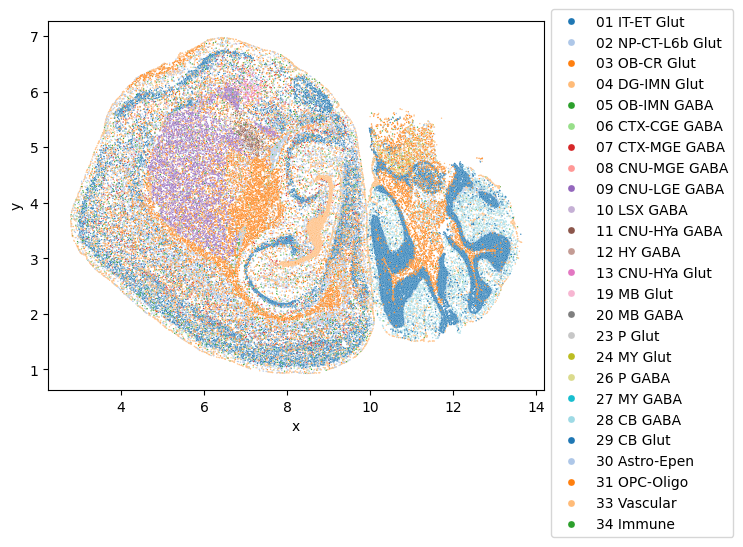

In [63]:
import seaborn as sns
ax=sns.scatterplot(
    x=st_data.obs['x'],
    y=st_data.obs['y'],
    hue=st_data.obs['class'],
    s=1,
    palette='tab20'
)
ax.legend(bbox_to_anchor=(1,1.05),markerscale=5)